<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/00_simulacionesml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulación de ML Notebooks

## 🗺️ Mapa del proceso de Machine Learning

Este notebook simula, de forma simplificada, las etapas típicas de un proyecto de Machine Learning:

1. **Librerías y configuraciones previas** – herramientas que usaremos.
2. **Funciones** – utilidades reutilizables (graficación, métricas, etc.).
3. **Carga del dataset** – obtención y primera inspección de los datos.
4. **Visualización de datos (EDA)** – entender las variables de entrada y de salida.
5. **Preparación de datos** – imputaciones, valores atípicos, transformaciones y codificación.
6. **Creación del modelo** – dividir los datos, escalar variables y entrenar.
7. **Afinando el modelo (tuning)** – compensar el desbalance de clases para mejorar el desempeño.
8. **Prueba** – validar el modelo con ejemplos concretos.

Cada sección numerada del notebook corresponde a una de estas etapas.

## 🎯 El problema que vamos a resolver

Un banco quiere averiguar **cuáles de sus clientes probablemente estarán en mora** en el pago de sus deudas. Para hacerlo cuenta con datos históricos de sus créditos: características del cliente y del préstamo, y si finalmente resultó ser un **buen** o un **mal crédito**.

- **Datos:** *German Credit* — 1000 clientes con 20 características (estado de la cuenta, historial de crédito, propósito y monto del préstamo, edad, empleo, etc.).
- **Variable que se quiere predecir (salida):** `bad_credit` → 0 = buen crédito, 1 = mal crédito.
- **Tipo de problema:** clasificación binaria supervisada.

> **Nota ética:** este dataset incluye variables sensibles (por ejemplo `gender_status`, `age_yrs` y `foreign_worker`). En un caso real, usarlas para decidir sobre créditos puede generar discriminación y está regulado; aquí se conservan solo con fines didácticos.

## 1. Librerias y configuraciones previas


In [ ]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np

# Preprocesado y modelado
# ==============================================================================

#Separar los datos entrenamiento y prueba
from sklearn.model_selection import train_test_split

#Escalar Variables
from sklearn.preprocessing import MinMaxScaler

#Creación de modelo
from sklearn.ensemble import RandomForestClassifier

#Evaluación del modelo
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score,
                             classification_report)

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [ ]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '02_GermanCredit.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [ ]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio especificado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [ ]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [ ]:
## Configuración entorno Colab

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

Descargando dataset desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/datasets/02_GermanCredit.csv
dataset descargado exitosamente a: datasets/02_GermanCredit.csv
Descargando funciones desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/utils/funciones.py
funciones descargado exitosamente a: utils/funciones.py


## 2. Funciones

En esta sección importamos las funciones reutilizables de `funciones.py` (descargado arriba). Aunque aca no se usa; en los notebooks posteriores se usan estas utilidades (curva ROC, VIF, matriz de correlación, etc.).

In [ ]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

# Importa funciones externas
#from funciones import multiple_plot

## 3. Carga del dataset

In [ ]:
#Se crea un dataframe d con los datos obtenidos de archivo de entrada
d = pd.read_csv(local_dataset_path)

In [ ]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Customer ID               1000 non-null   int64 
 1   checking_account_status   1000 non-null   object
 2   loan_duration_mo          1000 non-null   int64 
 3   credit_history            1000 non-null   object
 4   purpose                   1000 non-null   object
 5   loan_amount               1000 non-null   int64 
 6   savings_account_balance   1000 non-null   object
 7   time_employed_yrs         1000 non-null   object
 8   payment_pcnt_income       1000 non-null   int64 
 9   gender_status             1000 non-null   object
 10  other_signators           1000 non-null   object
 11  time_in_residence         1000 non-null   int64 
 12  property                  1000 non-null   object
 13  age_yrs                   1000 non-null   int64 
 14  other_credit_outstanding 

In [ ]:
d.head(2)

,Customer ID,checking_account_status,loan_duration_mo,credit_history,purpose,loan_amount,savings_account_balance,time_employed_yrs,payment_pcnt_income,gender_status,...,property,age_yrs,other_credit_outstanding,home_ownership,number_loans,job_category,dependents,telephone,foreign_worker,bad_credit
0,1122334,< 0 DM,6,critical account - other non-bank loans,radio/television,1169,unknown/none,>= 7 years,4,male-single,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,6156361,0 - 200 DM,48,current loans paid,radio/television,5951,< 100 DM,1 - 4 years,2,female-divorced/separated/married,...,real estate,22,none,own,1,skilled,1,none,yes,1


In [ ]:
#Borrando columnas innecesarias: 'Customer ID' es solo un identificador y no aporta información para predecir
d.drop(['Customer ID'], axis='columns', inplace=True)

In [ ]:
# Transformación del tipo de dato de la variable loan_amount
# realmente es un ejemplo dado que no es necesario porque la variable es originalmente numérica

d['loan_amount'] = pd.to_numeric(d['loan_amount'])

In [ ]:
#Verificación y eliminación de registros duplicados

#Verificación de registros duplicados
d.loc[d.duplicated()]

,checking_account_status,loan_duration_mo,credit_history,purpose,loan_amount,savings_account_balance,time_employed_yrs,payment_pcnt_income,gender_status,other_signators,...,property,age_yrs,other_credit_outstanding,home_ownership,number_loans,job_category,dependents,telephone,foreign_worker,bad_credit


In [ ]:
# eliminación de registros duplicados
d = d.drop_duplicates()

#Reiniciar el indice
d.reset_index(drop=True, inplace=True)

In [ ]:
#verificacion de completitud de los datos
for col in d.columns:
    print (col, np.sum(pd.isnull(d[col])))

checking_account_status 0
loan_duration_mo 0
credit_history 0
purpose 0
loan_amount 0
savings_account_balance 0
time_employed_yrs 0
payment_pcnt_income 0
gender_status 0
other_signators 0
time_in_residence 0
property 0
age_yrs 0
other_credit_outstanding 0
home_ownership 0
number_loans 0
job_category 0
dependents 0
telephone 0
foreign_worker 0
bad_credit 0


## 4. Visualización de datos

### Variables de entrada

In [ ]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head()

,checking_account_status,credit_history,purpose,savings_account_balance,time_employed_yrs,gender_status,other_signators,property,other_credit_outstanding,home_ownership,job_category,telephone,foreign_worker
0,< 0 DM,critical account - other non-bank loans,radio/television,unknown/none,>= 7 years,male-single,none,real estate,none,own,skilled,yes,yes
1,0 - 200 DM,current loans paid,radio/television,< 100 DM,1 - 4 years,female-divorced/separated/married,none,real estate,none,own,skilled,none,yes
2,none,critical account - other non-bank loans,education,< 100 DM,4 - 7 years,male-single,none,real estate,none,own,unskilled-resident,none,yes
3,< 0 DM,current loans paid,furniture/equipment,< 100 DM,4 - 7 years,male-single,guarantor,building society savings/life insurance,none,for free,skilled,none,yes
4,< 0 DM,past payment delays,car (new),< 100 DM,1 - 4 years,male-single,none,unknown-none,none,for free,skilled,none,yes


In [ ]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','int32','int64']).columns.tolist()
d[numCols].head()

,loan_duration_mo,loan_amount,payment_pcnt_income,time_in_residence,age_yrs,number_loans,dependents,bad_credit
0,6,1169,4,4,67,2,1,0
1,48,5951,2,2,22,1,1,1
2,12,2096,2,3,49,1,2,0
3,42,7882,2,4,45,1,2,0
4,24,4870,3,4,53,2,2,1


In [ ]:
#Se elimina la variable de salida 'bad_credit' de la lista de variables numéricas

numCols.remove('bad_credit')

### Variable de salida

In [ ]:
d.groupby('bad_credit').bad_credit.count().sort_values(ascending=False)

,bad_credit
bad_credit,
0,700
1,300


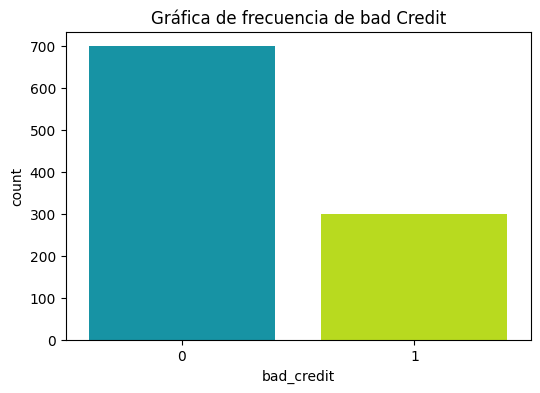

In [ ]:
plt.figure(figsize=(6,4))

plt.title('Gráfica de frecuencia de bad Credit')
sns.countplot(x=d['bad_credit'], palette='nipy_spectral')

plt.show()

## 5. Preparación de datos

### Imputaciones

En la sección 3 (`Carga del dataset`) ya verificamos que no hay valores nulos en ninguna columna, por lo que no se requiere ninguna imputación en este dataset. En otros datasets del curso (ver notebooks 01 en adelante) sí será necesario tratar valores faltantes.

### Valores atípicos para las variables de entrada

En este ejemplo no se realiza un tratamiento de valores atípicos porque el modelo que usaremos (Random Forest) se basa en árboles de decisión, los cuales son robustos frente a atípicos. Cuando se usan modelos sensibles a la escala o a la distribución (regresión lineal/logística, KNN, SVM), sí es importante identificarlos y tratarlos — ese proceso se muestra en detalle en los notebooks de regresión y clasificación (02 a 08).

### Transformaciones

Tampoco se aplican transformaciones adicionales (por ejemplo, logarítmicas) sobre las variables numéricas: Random Forest no requiere que las variables sigan una distribución particular. Más adelante, en la sección 6, sí escalamos las variables numéricas como buena práctica general, aunque para este modelo en particular no sea estrictamente necesario.

### Creación de Variables Dummies

In [ ]:
# Codificación one-hot de las variables categóricas con pd.get_dummies
# (drop_first=True elimina una categoría por variable para evitar redundancia)

d = pd.get_dummies(d, drop_first=True)

d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 49 columns):
 #   Column                                                  Non-Null Count  Dtype
---  ------                                                  --------------  -----
 0   loan_duration_mo                                        1000 non-null   int64
 1   loan_amount                                             1000 non-null   int64
 2   payment_pcnt_income                                     1000 non-null   int64
 3   time_in_residence                                       1000 non-null   int64
 4   age_yrs                                                 1000 non-null   int64
 5   number_loans                                            1000 non-null   int64
 6   dependents                                              1000 non-null   int64
 7   bad_credit                                              1000 non-null   int64
 8   checking_account_status_< 0 DM                          100

In [ ]:
d.head(3)

,loan_duration_mo,loan_amount,payment_pcnt_income,time_in_residence,age_yrs,number_loans,dependents,bad_credit,checking_account_status_< 0 DM,checking_account_status_> 200 DM or salary assignment,...,property_unknown-none,other_credit_outstanding_none,other_credit_outstanding_stores,home_ownership_own,home_ownership_rent,job_category_skilled,job_category_unemployed-unskilled-non-resident,job_category_unskilled-resident,telephone_yes,foreign_worker_yes
0,6,1169,4,4,67,2,1,0,True,False,...,False,True,False,True,False,True,False,False,True,True
1,48,5951,2,2,22,1,1,1,False,False,...,False,True,False,True,False,True,False,False,False,True
2,12,2096,2,3,49,1,2,0,False,False,...,False,True,False,True,False,False,False,True,False,True


## 6. Creación del modelo

### Dividir el conjunto de datos

In [ ]:
#Se establece las variables de entrada 'X' y la variable de salida 'y'
X = d.drop(columns ='bad_credit')
y = d['bad_credit']

In [ ]:
y

,bad_credit
0,0
1,1
2,0
3,0
4,1
...,...
995,0
996,0
997,0
998,1


In [ ]:
# Se crean los datasets de entrenamiento y prueba para las variables de entrada y salida
# stratify=y mantiene la misma proporción de buenos y malos créditos en entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y,
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True,
                                        stratify     = y
                                    )

# Copias independientes, para poder escalar columnas sin avisos de pandas
X_train = X_train.copy()
X_test = X_test.copy()

### Escalar Variables

In [ ]:
#Se establecen las variables numéricas a escalar

#Num_vars se le asigna la lista con las variables numéricas para posteriormente escalarlas
num_vars = numCols

print(num_vars)

['loan_duration_mo', 'loan_amount', 'payment_pcnt_income', 'time_in_residence', 'age_yrs', 'number_loans', 'dependents']


In [ ]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Se crea un objeto MinMaxScaler
scaler = MinMaxScaler()

# Se escalan los valores del dataset entrenamiento y prueba de las columnas numéricas
X_train[num_vars] = scaler.fit_transform(X_train[num_vars])
X_test[num_vars] = scaler.transform(X_test[num_vars])

X_train[num_vars].head()

,loan_duration_mo,loan_amount,payment_pcnt_income,time_in_residence,age_yrs,number_loans,dependents
429,0.3529,0.1372,1.0000,0.3333,0.1786,0.3333,0.0000
699,0.0294,0.0543,0.3333,1.0000,0.5536,0.0000,0.0000
46,0.4706,0.1127,1.0000,1.0000,0.3571,0.0000,0.0000
99,0.2353,0.3745,0.6667,1.0000,0.3036,0.3333,1.0000
664,0.2500,0.1096,1.0000,0.3333,0.5536,0.3333,0.0000


### Creación del modelo

In [ ]:
# Creación del modelo Random Forest con 10 árboles y 5 niveles de profundidad

modelo1 = RandomForestClassifier(
            n_estimators =  10,
            max_features =  'sqrt',
            max_depth    =  5,
            criterion    = 'gini',
            random_state =  1234
         )


# Entrenamiento del modelo

modelo1.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, n_estimators=10, random_state=1234)

### Evaluación del modelo

In [ ]:
# Ejecución del modelo con los datos de test
y_pred = modelo1.predict(X_test)

print("Random Forest:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Random Forest: 0.735
              precision    recall  f1-score   support

           0       0.73      0.98      0.84       140
           1       0.77      0.17      0.27        60

    accuracy                           0.73       200
   macro avg       0.75      0.57      0.56       200
weighted avg       0.74      0.73      0.67       200



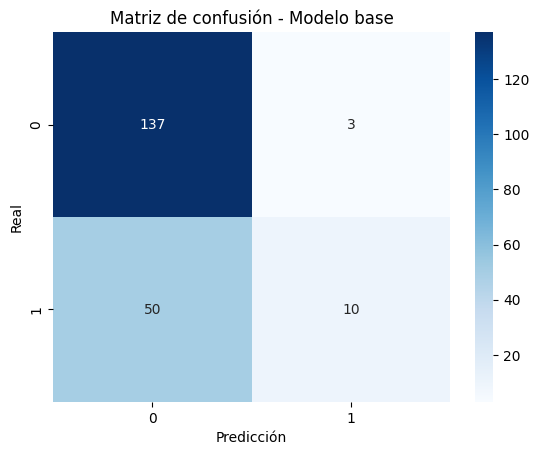

In [ ]:
# Matriz de confusión del modelo base (visualiza aciertos y errores por clase)

cm1 = confusion_matrix(y_test, y_pred)
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de confusión - Modelo base')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## 7. Afinando el modelo (tuning)

Como vimos en la sección 4, la variable de salida `bad_credit` está desbalanceada (700 casos "buen crédito" vs. 300 "mal crédito"). Esto hace que el modelo base tienda a favorecer la clase mayoritaria. Una forma sencilla de compensarlo es usar `class_weight="balanced"`, que le da más peso a los errores sobre la clase minoritaria durante el entrenamiento.

In [ ]:
# Creación del modelo Random Forest con 10 árboles, 5 niveles de profundidad
# y class_weight='balanced' para compensar el desbalance de clases

modelo2 = RandomForestClassifier(
            n_estimators =  10,
            max_features =  'sqrt',
            class_weight = "balanced",
            max_depth    =  5,
            criterion    = 'gini',
            random_state =  1234
         )


# Entrenamiento del modelo

modelo2.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=5, n_estimators=10,
                       random_state=1234)

### Evaluación del modelo

In [ ]:
# Ejecución del modelo con los datos de test

y_pred2 = modelo2.predict(X_test)

print("Random Forest:",accuracy_score(y_test, y_pred2))
print(classification_report(y_test, y_pred2))

Random Forest: 0.76
              precision    recall  f1-score   support

           0       0.85      0.80      0.82       140
           1       0.59      0.67      0.62        60

    accuracy                           0.76       200
   macro avg       0.72      0.73      0.72       200
weighted avg       0.77      0.76      0.76       200



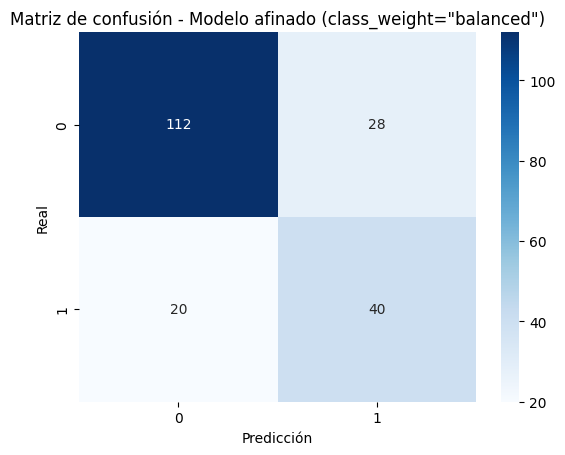

In [ ]:
# Matriz de confusión del modelo afinado (comparar con la del modelo base)

cm2 = confusion_matrix(y_test, y_pred2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de confusión - Modelo afinado (class_weight="balanced")')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

In [ ]:
# Comparación del recall de la clase minoritaria (bad_credit = 1): cuántos malos créditos detecta cada modelo
print(f"Recall de 'mal crédito' - modelo base:    {recall_score(y_test, y_pred):.2f}")
print(f"Recall de 'mal crédito' - modelo afinado: {recall_score(y_test, y_pred2):.2f}")

Recall de 'mal crédito' - modelo base:    0.17
Recall de 'mal crédito' - modelo afinado: 0.67


**Comparación:** con `class_weight="balanced"` el *recall* de la clase minoritaria (`bad_credit = 1`) sube de forma notable frente al modelo base (compara los dos valores impresos arriba): ahora el modelo detecta muchos más créditos malos, a cambio de una precisión algo menor. Este es un ejemplo típico del compromiso precisión-recall al tratar el desbalance de clases.

## 8. Prueba

### Evaluar algunas instancias (o ejemplos)

> **Nota:** esta muestra de 10 ejemplos es solo ilustrativa, para ver cómo predice el modelo caso por caso. La evaluación real y estadísticamente representativa del modelo ya se hizo arriba con las 200 observaciones del conjunto de prueba (`classification_report` y matrices de confusión).

In [ ]:
# Unir las variables de entrada de prueba con la variable de salida real
df_prep = X_test.copy()
df_prep['bad_credit_Real'] = y_test

In [ ]:
# Generar una muestra de 10 ejemplos de df_prep
x_i = df_prep.sample(n=10, random_state=123)
x_i

,loan_duration_mo,loan_amount,payment_pcnt_income,time_in_residence,age_yrs,number_loans,dependents,checking_account_status_< 0 DM,checking_account_status_> 200 DM or salary assignment,checking_account_status_none,...,other_credit_outstanding_none,other_credit_outstanding_stores,home_ownership_own,home_ownership_rent,job_category_skilled,job_category_unemployed-unskilled-non-resident,job_category_unskilled-resident,telephone_yes,foreign_worker_yes,bad_credit_Real
1,0.6471,0.3137,0.3333,0.3333,0.0536,0.0000,0.0000,False,False,False,...,True,False,True,False,True,False,False,False,True,1
644,0.1618,0.2406,0.6667,0.3333,0.3750,0.0000,0.0000,False,False,True,...,True,False,True,False,False,False,False,True,True,1
950,0.2059,0.1838,0.6667,0.6667,0.3750,0.6667,1.0000,False,False,False,...,True,False,True,False,False,True,False,True,True,0
357,0.0882,0.0262,1.0000,1.0000,0.4821,0.0000,0.0000,False,False,True,...,True,False,False,False,True,False,False,True,True,0
449,0.4706,0.0876,1.0000,1.0000,0.2679,0.0000,0.0000,True,False,False,...,True,False,True,False,True,False,False,True,True,1
74,0.4706,0.0950,1.0000,1.0000,0.3750,0.0000,0.0000,True,False,False,...,True,False,True,False,False,False,False,True,True,1
962,0.1618,0.1819,0.6667,0.3333,0.1786,0.0000,0.0000,False,False,True,...,True,False,True,False,True,False,False,False,True,0
170,0.2941,0.2048,0.3333,1.0000,0.1071,0.0000,0.0000,False,False,True,...,True,False,False,True,True,False,False,True,True,0
881,0.2941,0.4967,0.3333,1.0000,0.5179,0.0000,0.0000,False,False,True,...,True,False,False,False,True,False,False,True,True,0
219,0.4706,0.2016,0.3333,0.3333,0.0714,0.0000,0.0000,False,True,False,...,True,False,True,False,True,False,False,True,True,0


In [ ]:
# Predecir los valores para la muestra x_i utilizando el modelo2
resultadoPredict =modelo2.predict(x_i.drop(columns ='bad_credit_Real'))
resultadoPredict

array([1, 0, 0, 0, 1, 1, 0, 0, 0, 0])

In [ ]:
# Convertir el array numpy resultadoPredic en un DataFrame de pandas
resultadoPredict_df = pd.DataFrame(resultadoPredict, columns=['bad_credit_Predict'])

In [ ]:
# Concatenar x_i con el DataFrame de las predicciones
concatenated_df = pd.concat([x_i.reset_index(drop=True), resultadoPredict_df], axis=1)

concatenated_df[['bad_credit_Real', 'bad_credit_Predict']]

,bad_credit_Real,bad_credit_Predict
0,1,1
1,1,0
2,0,0
3,0,0
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,0,0


In [ ]:
# Crear una nueva columna llamada 'Clasificación' basada en las predicciones y los valores reales
concatenated_df['Clasificación'] = np.where(concatenated_df['bad_credit_Real'] == concatenated_df['bad_credit_Predict'], \
'Correcto', 'Incorrecto')

# Mostrar los resultados de la clasificación
concatenated_df[['bad_credit_Real', 'bad_credit_Predict', 'Clasificación']]

,bad_credit_Real,bad_credit_Predict,Clasificación
0,1,1,Correcto
1,1,0,Incorrecto
2,0,0,Correcto
3,0,0,Correcto
4,1,1,Correcto
5,1,1,Correcto
6,0,0,Correcto
7,0,0,Correcto
8,0,0,Correcto
9,0,0,Correcto


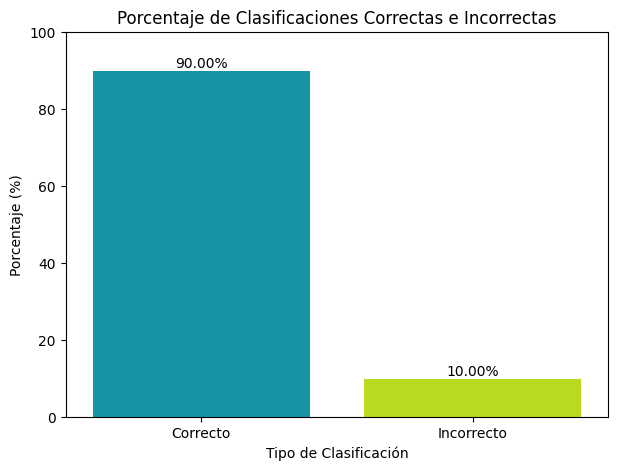

In [ ]:
# Calcular los porcentajes de clasificaciones correctas e incorrectas
classification_counts = concatenated_df['Clasificación'].value_counts(normalize=True).mul(100).reset_index()
classification_counts.columns = ['Clasificación', 'Porcentaje']

# Crear el gráfico de barras
plt.figure(figsize=(7, 5))
sns.barplot(x='Clasificación', y='Porcentaje', data=classification_counts, palette='nipy_spectral')

# Añadir etiquetas de porcentaje en las barras
for index, row in classification_counts.iterrows():
    plt.text(row.name, row.Porcentaje, f'{row.Porcentaje:.2f}%', color='black', ha="center", va='bottom')

plt.title('Porcentaje de Clasificaciones Correctas e Incorrectas')
plt.xlabel('Tipo de Clasificación')
plt.ylabel('Porcentaje (%)')
plt.ylim(0, 100) # Asegurar que el eje Y vaya hasta 100%
plt.show()